In [1]:
# ruff: noqa: T201, T203
from __future__ import annotations

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import logging

import pandas as pd
from dotenv import load_dotenv
from tqdm import tqdm

from config.config import DATA_DIR, RUN_DIR
from config.runs_vars import SUBSET_TO_DATASET_MAP
from src.evaluate import (
    analyze_results,
    get_predictions_with_gt,
    plot_usage_histograms,
    read_run_metrics_df,
    store_run_metrics_df,
)
from src.formatting import (
    format_oracle_pairs_filepath,
    format_run_path,
    format_storing_pathes_from_run_path,
    format_subsets_ontologies_paths,
)
from src.LLM_servers.openai import OpenAIServer
from src.onto_access import OntologyAccess
from src.onto_object import OntologyEntryAttr
from src.processing import parallel_samples_process, save_oracle_pairs_with_prompts
from src.prompts.prompts import (
    prompt_direct_entity,
    prompt_direct_entity_ontological,
    prompt_direct_entity_with_synonyms,
    prompt_sequential_hierarchy,
    prompt_sequential_hierarchy_ontological,
    prompt_sequential_hierarchy_with_synonyms,
)
from src.prompts.system import BASELINE_INITIALIZATION_MESSAGE
from src.utils import load_precomputed_oracle_pairs, read_oracle_pairs, save_run_results

logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
DATASET_NAME, SET_NAME = "anatomy", "mouse-human"
# DATASET_NAME, SET_NAME = "bioml-2024", "ncit-doid"

src_onto_path, tgt_onto_path = format_subsets_ontologies_paths(DATASET_NAME, SET_NAME)

In [6]:
EXP_NAMES_TO_PROMPT_FUNCTIONS = {
    prompt_function.__name__.replace("prompt_", ""): prompt_function
    for prompt_function in [
        prompt_direct_entity,
        prompt_direct_entity_ontological,
        prompt_sequential_hierarchy,
        prompt_sequential_hierarchy_ontological,
        prompt_direct_entity_with_synonyms,
        prompt_sequential_hierarchy_with_synonyms,
    ]
}

In [ ]:
onto_src = OntologyAccess(src_onto_path, annotate_on_init=True)
onto_tgt = OntologyAccess(tgt_onto_path, annotate_on_init=True)

### Pre-Validation

In [ ]:
src_entity, tgt_entity = read_oracle_pairs(format_oracle_pairs_filepath(DATASET_NAME, SET_NAME))[0]
try:
    src_entity, tgt_entity = OntologyEntryAttr(src_entity, onto_src), OntologyEntryAttr(tgt_entity, onto_tgt)
except AssertionError:
    src_entity, tgt_entity = OntologyEntryAttr(tgt_entity, onto_src), OntologyEntryAttr(src_entity, onto_tgt)

print(src_entity)
print(tgt_entity)

for name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
    print(f"Prompt function: {name}")
    print(prompt_function(src_entity, tgt_entity))
    print("=" * 50)

### Pre-Processing

In [ ]:
ALL_DATASET_NAMES = {
    "anatomy": ["mouse-human"],
    # "bioml-2024": ["ncit-doid", "omim-ordo"],
    # "largebio": ["fma-nci", "fma-snomed", "snomed-nci"],
}
PAIRS_WITH_PROMPTS_SUBDIR = "oracle_pairs"
oracle_prompt_functions = list(EXP_NAMES_TO_PROMPT_FUNCTIONS.values())

for dataset_name, set_names in ALL_DATASET_NAMES.items():
    for set_name in set_names:
        try:
            ontologies_access = []
            for onto_path in tqdm(
                format_subsets_ontologies_paths(dataset_name, set_name),
                desc=f"Loading ontologies: {dataset_name} - {set_name}",
            ):
                ontologies_access.append(OntologyAccess(onto_path, annotate_on_init=True))

            oracle_candidate_pairs_path = format_oracle_pairs_filepath(dataset_name, set_name)
            oracle_pairs_save_dir = DATA_DIR / dataset_name / set_name / PAIRS_WITH_PROMPTS_SUBDIR

            with_prompts_df = save_oracle_pairs_with_prompts(
                oracle_candidate_pairs_path, *ontologies_access, oracle_prompt_functions, oracle_pairs_save_dir, sep="|"
            )
        except Exception as e:
            print(f"Error processing {dataset_name} - {set_name}: {e}")
            continue

Adding prompts:   9%|▊         | 34/398 [00:04<00:53,  6.79it/s]

### Run experiments


In [4]:
onto_src, onto_tgt = None, None

Processing Lines prompt_direct_entity: 100%|██████████| 398/398 [00:15<00:00, 25.19it/s] 


Mean input tockens: 103.1
Mean output tockens: 9.0
Total input tockens: 41046
Total output tockens: 3582


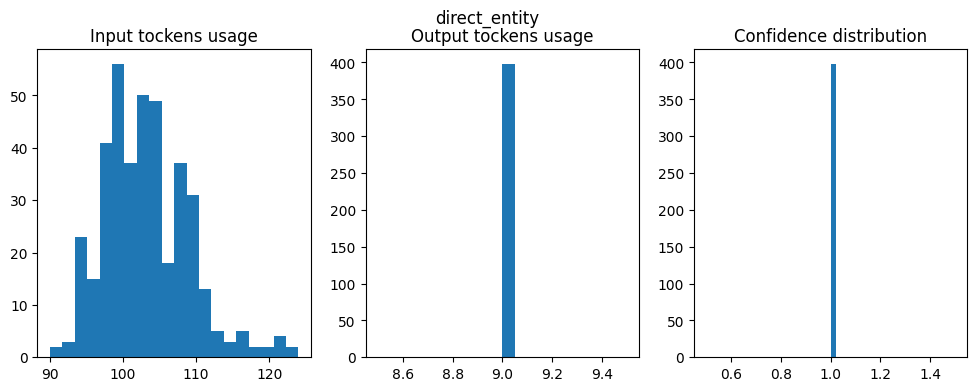

Accuracy: 0.887
Precision: 0.882
Recall: 0.976
F1 Score: 0.927


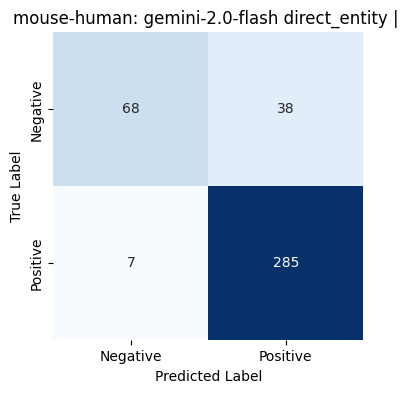

Processing Lines prompt_direct_entity_ontological: 100%|██████████| 398/398 [00:14<00:00, 26.56it/s]


Mean input tockens: 139.8
Mean output tockens: 9.0
Total input tockens: 55625
Total output tockens: 3582


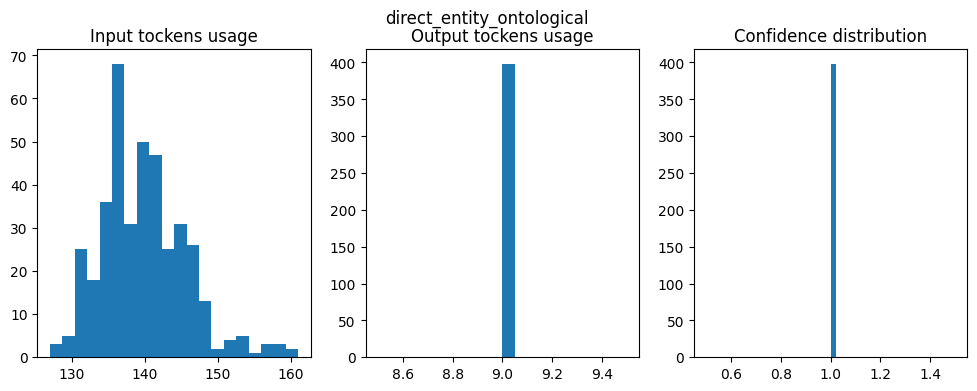

Accuracy: 0.776
Precision: 0.880
Recall: 0.805
F1 Score: 0.841


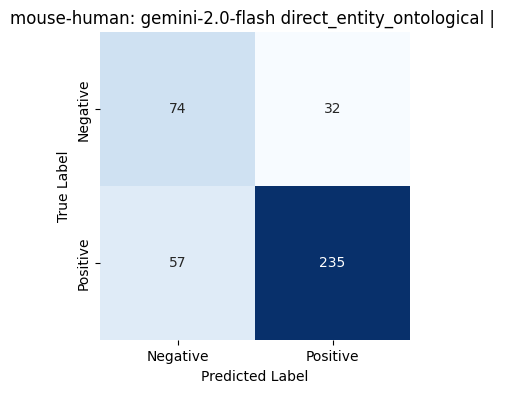

Processing Lines prompt_sequential_hierarchy: 100%|██████████| 398/398 [00:12<00:00, 32.75it/s] 


Mean input tockens: 122.7
Mean output tockens: 9.0
Total input tockens: 48840
Total output tockens: 3582


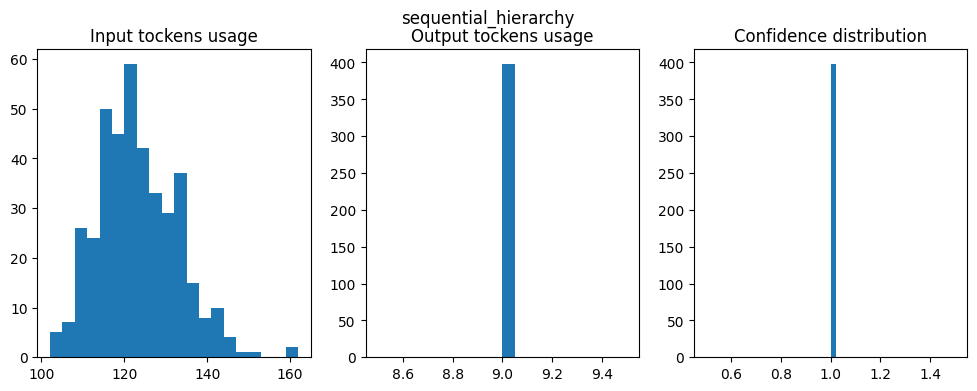

Accuracy: 0.834
Precision: 0.832
Recall: 0.969
F1 Score: 0.896


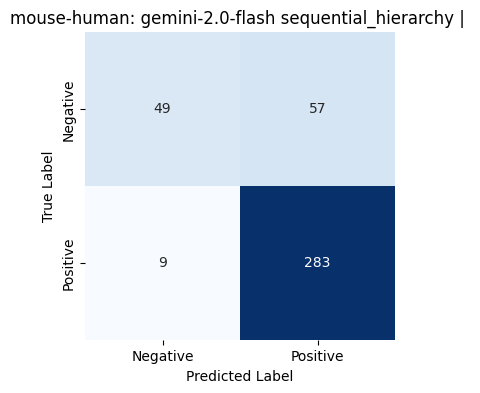

Processing Lines prompt_sequential_hierarchy_ontological: 100%|██████████| 398/398 [00:14<00:00, 27.95it/s]


Mean input tockens: 177.9
Mean output tockens: 9.0
Total input tockens: 70809
Total output tockens: 3582


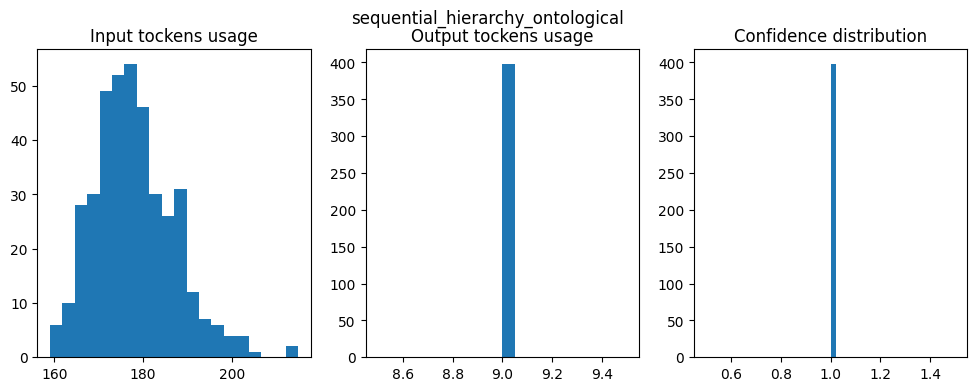

Accuracy: 0.802
Precision: 0.842
Recall: 0.897
F1 Score: 0.869


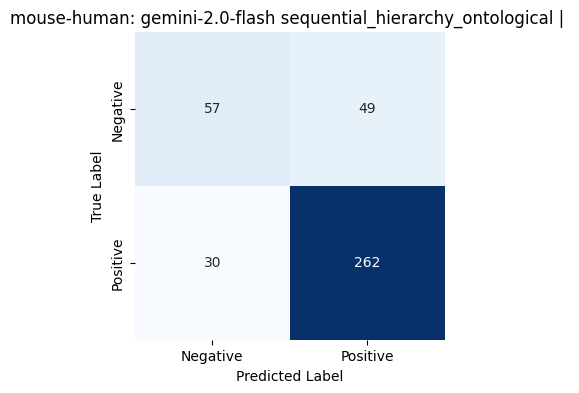

Processing Lines prompt_direct_entity_with_synonyms:  96%|█████████▋| 384/398 [00:33<00:00, 62.60it/s]

In [ ]:
MAX_WORKERS = 100
MODEL = "gemini-2.0-flash"  # "gpt-4o-mini"

if MODEL.startswith("gemini"):
    llm_oracle = OpenAIServer(
        api_key=os.environ["GEMINI_API_KEY"], base_url="https://generativelanguage.googleapis.com/v1beta/openai/"
    )
else:
    llm_oracle = OpenAIServer(api_key=os.environ["OPENAI_API_KEY"])
llm_oracle.add_system_context(BASELINE_INITIALIZATION_MESSAGE)

oracle_candidate_pairs = read_oracle_pairs(format_oracle_pairs_filepath(DATASET_NAME, SET_NAME))[:]

run_path = format_run_path()

for current_exp_name, prompt_function in EXP_NAMES_TO_PROMPT_FUNCTIONS.items():
    oracle_candidate_pairs = load_precomputed_oracle_pairs(DATASET_NAME, SET_NAME, prompt_function)

    results, tokens_usage, confidences = parallel_samples_process(
        oracle_candidate_pairs, llm_oracle, onto_src, onto_tgt, MODEL, MAX_WORKERS, prompt_function
    )
    prediction_path, stats_path, diagram_path = format_storing_pathes_from_run_path(
        run_path, SET_NAME, MODEL, current_exp_name, suffix=""
    )
    save_run_results(results, prediction_path, columns=["Source", "Target", "Prediction", "Confidence"])

    plot_usage_histograms(tokens_usage, confidences, do_plot=True, do_print=True, suptitle=current_exp_name)

    try:
        predictions = get_predictions_with_gt(run_path, DATASET_NAME, SET_NAME, MODEL, current_exp_name, suffix="")
        analyze_results(
            predictions,
            print_results=True,
            plot_confusion_matrix=True,
            subtitle=f"{SET_NAME}: {MODEL} {current_exp_name} | ",
            cm_save_path=diagram_path,
            stats_path=stats_path,
        )
    except Exception as e:  # noqa: BLE001
        print(f"Error: {e}")

    print("\n")

store_run_metrics_df(EXP_NAMES_TO_PROMPT_FUNCTIONS, run_path, DATASET_NAME, SET_NAME, MODEL)

## Analysis


In [ ]:
runs_array = []

for directory in sorted(RUN_DIR.iterdir(), key=lambda x: x.name, reverse=True):
    if not directory.is_dir():
        continue
    for file in directory.iterdir():
        if '_' not in file.name:
            continue
        subset_name, model_name = file.name.split('_')[:2]
        dataset_name = SUBSET_TO_DATASET_MAP.get(subset_name)
    runs_array.append((directory.name, model_name, subset_name, dataset_name))

runs_array

[('2025-04-10_22-11-36', 'gemini-2.0-flash', 'ncit-doid', 'bioml-2024'),
 ('2025-04-10_00-33-19', 'gemini-2.0-flash-lite', 'ncit-doid', 'bioml-2024'),
 ('2025-04-06_22-05-02', 'gemini-2.0-flash-lite', 'omim-ordo', 'bioml-2024'),
 ('2025-04-06_19-27-41', 'gemini-2.0-flash', 'omim-ordo', 'bioml-2024'),
 ('2025-04-06_14-51-00', 'gemini-2.0-flash-lite', 'fma-nci', 'largebio'),
 ('2025-04-06_14-18-46', 'gemini-2.0-flash', 'fma-nci', 'largebio'),
 ('2025-04-04_19-41-28', 'gemini-2.0-flash', 'human-mouse', 'anatomy'),
 ('2025-04-04_19-23-47', 'gemini-2.0-flash-lite', 'human-mouse', 'anatomy'),
 ('2025-04-04_00-43-16', 'gemini-2.0-flash', 'fma-snomed', 'largebio'),
 ('2025-03-28_10-15-04', 'gpt-4o-mini', 'fma-nci', 'largebio'),
 ('2025-03-19_23-32-20', 'gpt-4o-mini', 'omim-ordo', 'bioml-2024'),
 ('2025-03-19_22-17-52', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),
 ('2025-03-19_19-48-41', 'gpt-4o-mini', 'human-mouse', 'anatomy'),
 ('2025-03-14_00-40-55', 'gpt-4o-mini', 'ncit-doid', 'bioml-2024'),

In [ ]:
runs = [
    ('2025-04-10_22-11-36', 'gemini-2.0-flash', 'ncit-doid', 'bioml-2024'),
    ("2025-04-10_00-33-19", "gemini-2.0-flash-lite", "ncit-doid", "bioml-2024"),
    ("2025-04-06_22-05-02", "gemini-2.0-flash-lite", "omim-ordo", "bioml-2024"),
    ("2025-04-06_19-27-41", "gemini-2.0-flash", "omim-ordo", "bioml-2024"),
    ("2025-04-06_14-51-00", "gemini-2.0-flash-lite", "fma-nci", "largebio"),
    ("2025-04-06_14-18-46", "gemini-2.0-flash", "fma-nci", "largebio"),
    ("2025-04-04_19-41-28", "gemini-2.0-flash", "human-mouse", "anatomy"),
    ("2025-04-04_19-23-47", "gemini-2.0-flash-lite", "human-mouse", "anatomy"),
    ("2025-04-04_00-43-16", "gemini-2.0-flash", "fma-snomed", "largebio"),
    ("2025-03-28_10-15-04", "gpt-4o-mini", "fma-nci", "largebio"),
    ("2025-03-19_23-32-20", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
    ("2025-03-19_22-17-52", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-19_19-48-41", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-14_00-40-55", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-12_17-21-53", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-12_14-43-32", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
]

dfs = []

for run_subdir, model, set_name, dataset in runs:
    metrics_df = read_run_metrics_df(run_subdir)
    for col, value in zip(["Dataset", "SubSet", "Model"], [dataset, set_name, model]):
        if col not in metrics_df.columns:
            metrics_df[col] = value
    metrics_df["Run"] = run_subdir
    dfs.append(metrics_df)

results_df = pd.concat(dfs, ignore_index=True)
results_df = results_df.sort_values(by=["Dataset", "SubSet", "Model", "Experiment"])
pd.set_option("display.max_rows", None)

results_df

,Experiment,Accuracy,Precision,Recall,F1 Score,Dataset,SubSet,Model,Run
36,direct_entity,0.8392,0.8476,0.9521,0.8968,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
37,direct_entity_ontological,0.8266,0.8495,0.9281,0.8871,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
40,direct_entity_with_synonyms,0.8492,0.8392,0.9829,0.9054,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
38,sequential_hierarchy,0.8442,0.8423,0.9692,0.9013,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
39,sequential_hierarchy_ontological,0.7990,0.8354,0.9041,0.8684,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
41,sequential_hierarchy_with_synonyms,0.8518,0.8416,0.9829,0.9068,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
42,direct_entity,0.8090,0.9000,0.8322,0.8648,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
43,direct_entity_ontological,0.7186,0.8947,0.6986,0.7846,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
46,direct_entity_with_synonyms,0.8141,0.8283,0.9418,0.8814,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47
44,sequential_hierarchy,0.8266,0.8495,0.9281,0.8871,anatomy,human-mouse,gemini-2.0-flash-lite,2025-04-04_19-23-47


In [ ]:
results_df.to_csv(RUN_DIR / "all_runs_metrics.csv", index=False)